In [1]:
#  "PARKINSON'S PROGRESSION MONITORING "
    

In [2]:
# importing libraries 

# for numerical data analysis
import pandas as pd
import numpy as np

# for visualizations
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# Loading dataset
data=pd.read_csv("data_parkinson's.csv")
data.head(10)

,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
0,1,72,0,5.6431,28.199,34.398,0.00662,0.000034,0.00401,0.00317,...,0.230,0.01438,0.01309,0.01662,0.04314,0.014290,21.640,0.41888,0.54842,0.16006
1,1,72,0,12.6660,28.447,34.894,0.00300,0.000017,0.00132,0.00150,...,0.179,0.00994,0.01072,0.01689,0.02982,0.011112,27.183,0.43493,0.56477,0.10810
2,1,72,0,19.6810,28.695,35.389,0.00481,0.000025,0.00205,0.00208,...,0.181,0.00734,0.00844,0.01458,0.02202,0.020220,23.047,0.46222,0.54405,0.21014
3,1,72,0,25.6470,28.905,35.810,0.00528,0.000027,0.00191,0.00264,...,0.327,0.01106,0.01265,0.01963,0.03317,0.027837,24.445,0.48730,0.57794,0.33277
4,1,72,0,33.6420,29.187,36.375,0.00335,0.000020,0.00093,0.00130,...,0.176,0.00679,0.00929,0.01819,0.02036,0.011625,26.126,0.47188,0.56122,0.19361
5,1,72,0,40.6520,29.435,36.870,0.00353,0.000023,0.00119,0.00159,...,0.214,0.01006,0.01337,0.02263,0.03019,0.009438,22.946,0.53949,0.57243,0.19500
6,1,72,0,47.6490,29.682,37.363,0.00422,0.000024,0.00212,0.00221,...,0.445,0.02376,0.02621,0.03488,0.07128,0.013260,22.506,0.49250,0.54779,0.17563
7,1,72,0,54.6400,29.928,37.857,0.00476,0.000025,0.00226,0.00259,...,0.212,0.00979,0.01462,0.01911,0.02937,0.027969,22.929,0.47712,0.54234,0.23844
8,1,72,0,61.6690,30.177,38.353,0.00432,0.000029,0.00156,0.00207,...,0.371,0.01774,0.02134,0.03451,0.05323,0.013381,22.078,0.51563,0.61864,0.20037
9,1,72,0,68.6880,30.424,38.849,0.00496,0.000027,0.00258,0.00253,...,0.310,0.02030,0.01970,0.02569,0.06089,0.018021,22.606,0.50032,0.58673,0.20117


In [4]:
print(data.info())                          # Basic info about data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5875 entries, 0 to 5874
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   subject#       5875 non-null   int64  
 1   age            5875 non-null   int64  
 2   sex            5875 non-null   int64  
 3   test_time      5875 non-null   float64
 4   motor_UPDRS    5875 non-null   float64
 5   total_UPDRS    5875 non-null   float64
 6   Jitter(%)      5875 non-null   float64
 7   Jitter(Abs)    5875 non-null   float64
 8   Jitter:RAP     5875 non-null   float64
 9   Jitter:PPQ5    5875 non-null   float64
 10  Jitter:DDP     5875 non-null   float64
 11  Shimmer        5875 non-null   float64
 12  Shimmer(dB)    5875 non-null   float64
 13  Shimmer:APQ3   5875 non-null   float64
 14  Shimmer:APQ5   5875 non-null   float64
 15  Shimmer:APQ11  5875 non-null   float64
 16  Shimmer:DDA    5875 non-null   float64
 17  NHR            5875 non-null   float64
 18  HNR     

In [5]:
data.describe()                     # Descriptive statistics for numerical features

,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
count,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,...,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000,5875.000000
mean,21.494128,64.804936,0.317787,92.863722,21.296229,29.018942,0.006154,0.000044,0.002987,0.003277,...,0.310960,0.017156,0.020144,0.027481,0.051467,0.032120,21.679495,0.541473,0.653240,0.219589
std,12.372279,8.821524,0.465656,53.445602,8.129282,10.700283,0.005624,0.000036,0.003124,0.003732,...,0.230254,0.013237,0.016664,0.019986,0.039711,0.059692,4.291096,0.100986,0.070902,0.091498
min,1.000000,36.000000,0.000000,-4.262500,5.037700,7.000000,0.000830,0.000002,0.000330,0.000430,...,0.026000,0.001610,0.001940,0.002490,0.004840,0.000286,1.659000,0.151020,0.514040,0.021983
25%,10.000000,58.000000,0.000000,46.847500,15.000000,21.371000,0.003580,0.000022,0.001580,0.001820,...,0.175000,0.009280,0.010790,0.015665,0.027830,0.010955,19.406000,0.469785,0.596180,0.156340
50%,22.000000,65.000000,0.000000,91.523000,20.871000,27.576000,0.004900,0.000034,0.002250,0.002490,...,0.253000,0.013700,0.015940,0.022710,0.041110,0.018448,21.920000,0.542250,0.643600,0.205500
75%,33.000000,72.000000,1.000000,138.445000,27.596500,36.399000,0.006800,0.000053,0.003290,0.003460,...,0.365000,0.020575,0.023755,0.032715,0.061735,0.031463,24.444000,0.614045,0.711335,0.264490
max,42.000000,85.000000,1.000000,215.490000,39.511000,54.992000,0.099990,0.000446,0.057540,0.069560,...,2.107000,0.162670,0.167020,0.275460,0.488020,0.748260,37.875000,0.966080,0.865600,0.731730


In [6]:
print(data.nunique())                       # Total unique values in each columns

subject#           42
age                23
sex                 2
test_time        2442
motor_UPDRS      1080
total_UPDRS      1129
Jitter(%)        1305
Jitter(Abs)      1326
Jitter:RAP        853
Jitter:PPQ5       840
Jitter:DDP       1703
Shimmer          3581
Shimmer(dB)       852
Shimmer:APQ3     2664
Shimmer:APQ5     2850
Shimmer:APQ11    3283
Shimmer:DDA      4223
NHR              5532
HNR              4780
RPDE             5430
DFA              5282
PPE              4777
dtype: int64


In [7]:
print(data.isnull().sum())                 # Null values 
print("=================\n")
print(data.duplicated().sum())                  # checking for duplicated entries






subject#         0
age              0
sex              0
test_time        0
motor_UPDRS      0
total_UPDRS      0
Jitter(%)        0
Jitter(Abs)      0
Jitter:RAP       0
Jitter:PPQ5      0
Jitter:DDP       0
Shimmer          0
Shimmer(dB)      0
Shimmer:APQ3     0
Shimmer:APQ5     0
Shimmer:APQ11    0
Shimmer:DDA      0
NHR              0
HNR              0
RPDE             0
DFA              0
PPE              0
dtype: int64

0


In [8]:
print(data['subject#'].value_counts(ascending=True)) # Total value counts per subject/participant

subject#
32    101
12    107
22    112
13    112
21    123
18    126
30    126
27    129
19    129
36    129
31    130
26    130
20    134
28    134
33    135
14    136
4     137
23    138
16    138
11    138
37    140
40    142
15    143
39    143
25    144
17    144
3     144
2     145
10    148
1     149
38    149
8     150
42    150
9     152
5     156
24    156
6     156
7     161
34    161
35    165
41    165
29    168
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

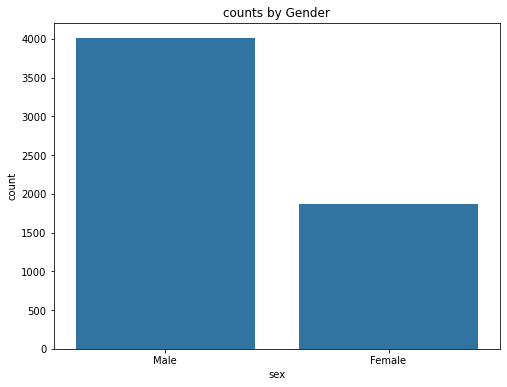

In [9]:
# count plot for participant by gender

plt.figure(figsize=(8,6))
sns.countplot(data=data, x='sex')
plt.title("counts by Gender")
plt.xticks([0,1], ['Male', 'Female'])
plt.show

Most of the participants are male by gender.

<function matplotlib.pyplot.show(close=None, block=None)>

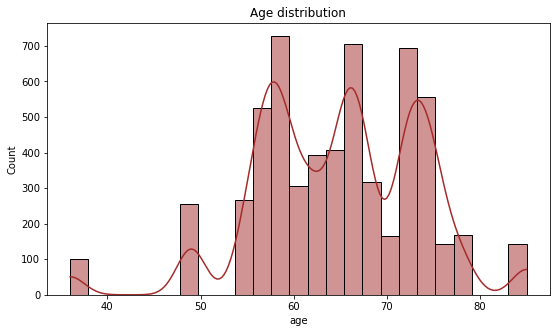

In [10]:
# histogram for Age distribution
plt.figure(figsize=(9,5))
sns.histplot(data['age'], bins=25, kde=True, color='brown')
plt.title("Age distribution")
plt.show

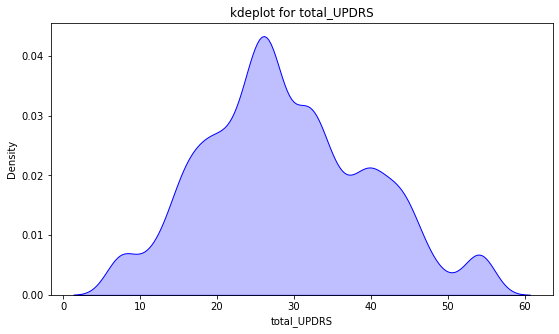

In [11]:
# total_UPDRS visualization
plt.figure(figsize=(9,5))
sns.kdeplot(data['total_UPDRS'], shade=True, color='blue')
plt.title("kdeplot for total_UPDRS")
plt.show()

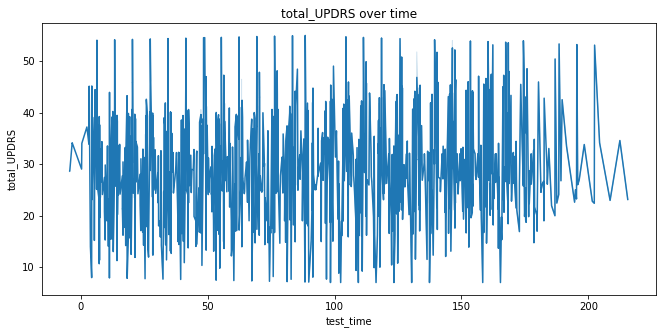

In [12]:
# for total_UPDRS trend over time 
plt.figure(figsize=(11,5))
sns.lineplot(data=data, x='test_time', y='total_UPDRS')
plt.title("total_UPDRS over time")
plt.show()

<Axes: xlabel='total_UPDRS', ylabel='Count'>

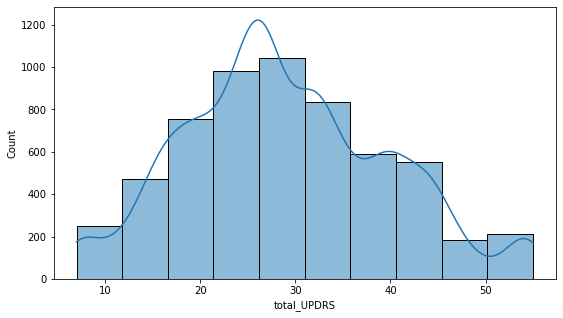

In [13]:
plt.figure(figsize=(9,5))
sns.histplot(data['total_UPDRS'], bins=10, kde=True)  # total_UPDRS distribution


In [14]:
# features correlation
cor=data.corr(numeric_only=True)
cor


,subject#,age,sex,test_time,motor_UPDRS,total_UPDRS,Jitter(%),Jitter(Abs),Jitter:RAP,Jitter:PPQ5,...,Shimmer(dB),Shimmer:APQ3,Shimmer:APQ5,Shimmer:APQ11,Shimmer:DDA,NHR,HNR,RPDE,DFA,PPE
subject#,1.000000,-0.030864,0.286851,-0.000882,0.252919,0.253643,0.135448,0.075147,0.120339,0.136474,...,0.142864,0.112950,0.138264,0.173333,0.112949,0.168743,-0.206929,0.147300,0.097464,0.157559
age,-0.030864,1.000000,-0.041602,0.019884,0.273665,0.310290,0.023071,0.035685,0.010255,0.013199,...,0.111130,0.098912,0.089983,0.135238,0.098913,0.007093,-0.104842,0.090208,-0.092870,0.120790
sex,0.286851,-0.041602,1.000000,-0.009805,-0.031205,-0.096559,0.051422,-0.154661,0.076718,0.087995,...,0.056481,0.044937,0.064819,0.023360,0.044938,0.168170,-0.000167,-0.159262,-0.165113,-0.099901
test_time,-0.000882,0.019884,-0.009805,1.000000,0.067918,0.075263,-0.022837,-0.011349,-0.028888,-0.023290,...,-0.030962,-0.029020,-0.036504,-0.039110,-0.029017,-0.026357,0.036545,-0.038887,0.019261,-0.000563
motor_UPDRS,0.252919,0.273665,-0.031205,0.067918,1.000000,0.947231,0.084816,0.050899,0.072684,0.076291,...,0.110076,0.084261,0.092105,0.136560,0.084260,0.074967,-0.157029,0.128607,-0.116242,0.162433
total_UPDRS,0.253643,0.310290,-0.096559,0.075263,0.947231,1.000000,0.074247,0.066926,0.064015,0.063352,...,0.098790,0.079363,0.083467,0.120838,0.079363,0.060952,-0.162117,0.156897,-0.113475,0.156195
Jitter(%),0.135448,0.023071,0.051422,-0.022837,0.084816,0.074247,1.000000,0.865574,0.984181,0.968214,...,0.716704,0.664149,0.694002,0.645965,0.664147,0.825294,-0.675188,0.427128,0.226550,0.721849
Jitter(Abs),0.075147,0.035685,-0.154661,-0.011349,0.050899,0.066926,0.865574,1.000000,0.844622,0.790534,...,0.655866,0.623825,0.621397,0.589992,0.623823,0.699954,-0.706420,0.547097,0.352264,0.787848
Jitter:RAP,0.120339,0.010255,0.076718,-0.028888,0.072684,0.064015,0.984181,0.844622,1.000000,0.947196,...,0.685551,0.650226,0.659831,0.603082,0.650225,0.792373,-0.641473,0.382891,0.214881,0.670652
Jitter:PPQ5,0.136474,0.013199,0.087995,-0.023290,0.076291,0.063352,0.968214,0.790534,0.947196,1.000000,...,0.734591,0.676711,0.734021,0.668413,0.676710,0.864864,-0.662409,0.381503,0.175359,0.663491


<Axes: >

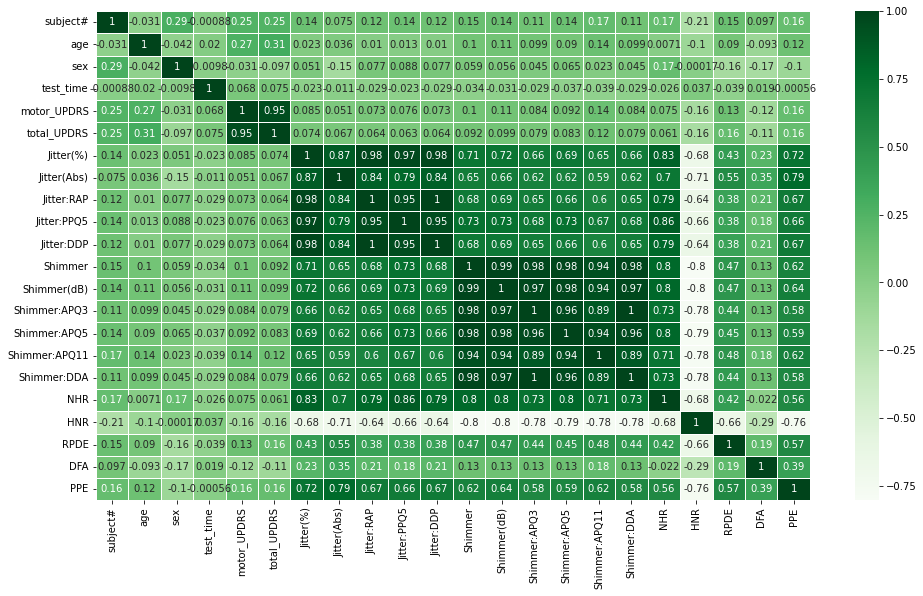

In [15]:
# Visualizing the Correlation
plt.figure(figsize=(16,9))
sns.heatmap(cor, annot=True, linewidth=0.5, linecolor='white', cmap='Greens')

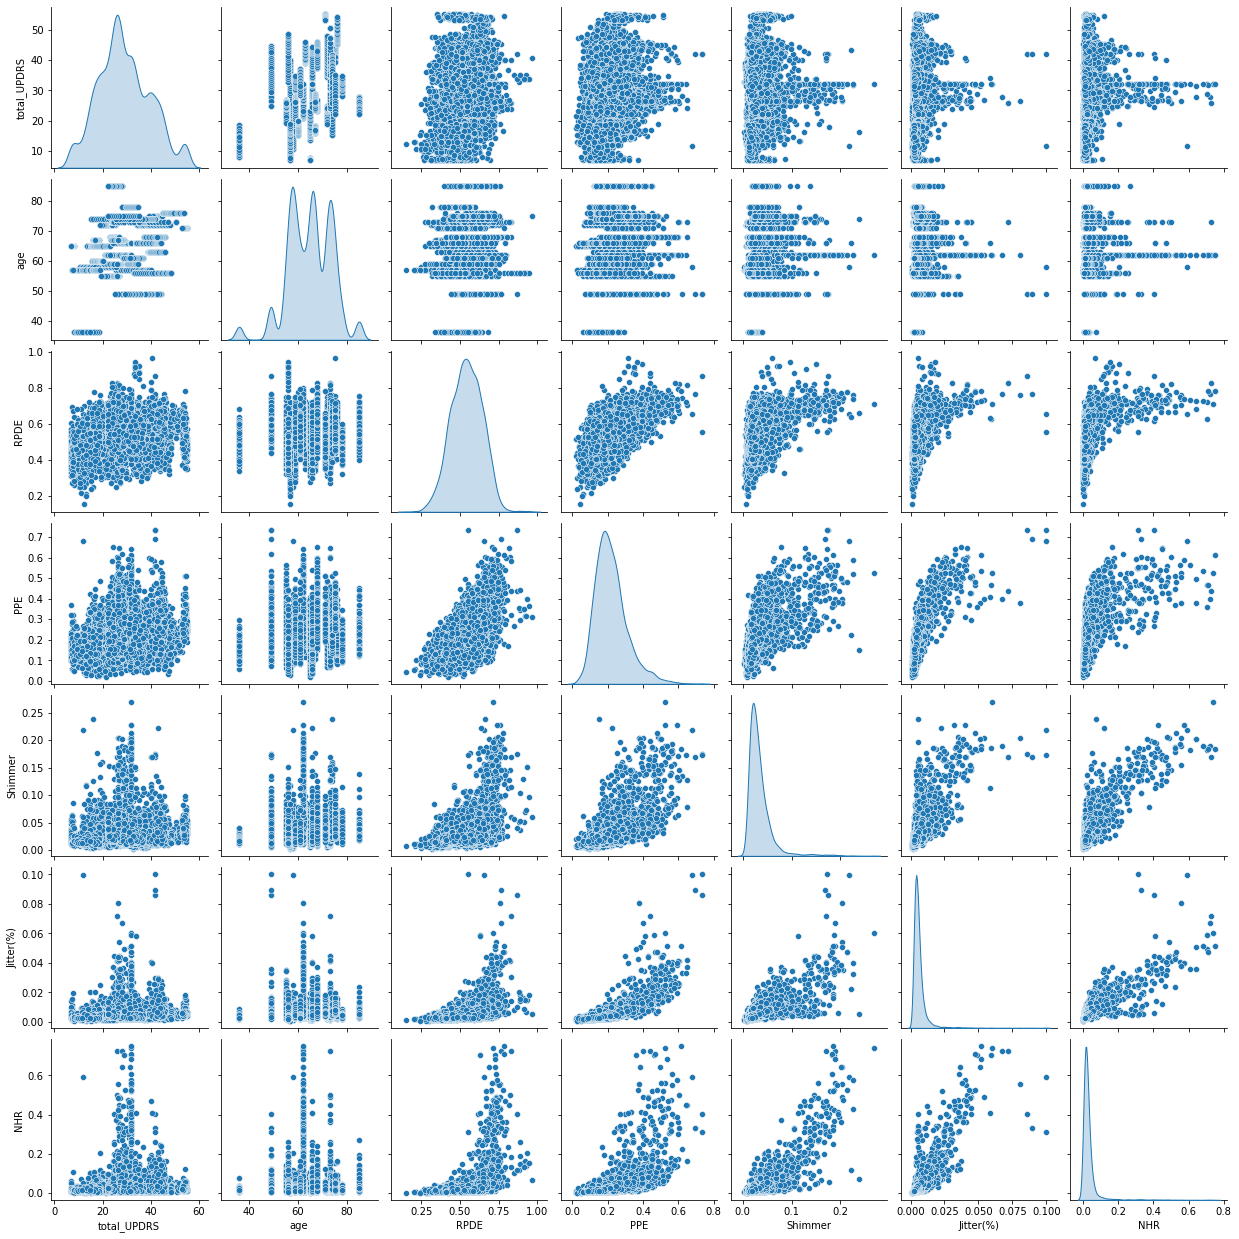

In [16]:
sns.pairplot(data,
             vars=['total_UPDRS','age','RPDE','PPE','Shimmer','Jitter(%)','NHR'],
             diag_kind='kde')

In [17]:
# feature coorelation with total_UPDRS only
data.corr(numeric_only=True)['total_UPDRS'].sort_values(ascending=False)

total_UPDRS      1.000000
motor_UPDRS      0.947231
age              0.310290
subject#         0.253643
RPDE             0.156897
PPE              0.156195
Shimmer:APQ11    0.120838
Shimmer(dB)      0.098790
Shimmer          0.092141
Shimmer:APQ5     0.083467
Shimmer:DDA      0.079363
Shimmer:APQ3     0.079363
test_time        0.075263
Jitter(%)        0.074247
Jitter(Abs)      0.066926
Jitter:DDP       0.064027
Jitter:RAP       0.064015
Jitter:PPQ5      0.063352
NHR              0.060952
sex             -0.096559
DFA             -0.113475
HNR             -0.162117
Name: total_UPDRS, dtype: float64

<Axes: >

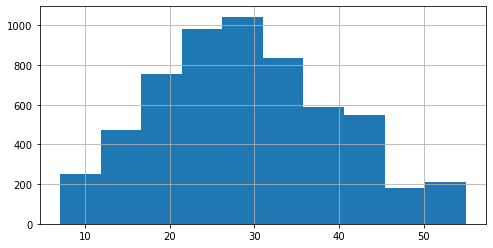

In [18]:
# Target variable distribution
plt.figure(figsize=(8,4))
data.groupby('subject#')['total_UPDRS'].agg('mean', 'min' , 'max', 'std')
data['total_UPDRS'].hist()

In [19]:
# Importing required packages
from sklearn.model_selection import train_test_split, GroupKFold  # for Random data split and k fold validation
from sklearn.preprocessing import StandardScaler, LabelEncoder  # for preprocessing the data
from sklearn.pipeline import make_pipeline                       # for making pipelines
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet, Lasso  
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.dummy import DummyRegressor      

from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score,mean_squared_error #Evalutaion metrics


In [20]:
# creating a ditionary for ML models

model={
    'Linear' :  LinearRegression(),
    'Ridge':  Ridge (),
    'Lasso': Lasso (),
    'ElasticNet' : ElasticNet (),
    'RandomForest' : RandomForestRegressor(),
    'XGB Reg' : XGBRegressor(),
    'Dummy': DummyRegressor (strategy='mean')
}




In [21]:
data['Sex']=LabelEncoder().fit_transform(data['sex'])  # label-encoding the sex column values

In [22]:

# Random Split

# droping columns 
X=data.drop(columns=['motor_UPDRS','sex','total_UPDRS'], axis=1)  

# target varible 
y=data['total_UPDRS']                                                            

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Some features are dropped from the X data:
1. total_UPDRS and motor_UPDRS scores are target variable and its other form respectively.
2. 'sex' is dropped as it is label encoded to new feature "Sex".

In [23]:
results1=[]



for names, models in model.items():
 
    pipeline=make_pipeline(
        
        
        StandardScaler(),
        models
        )
        
    pipeline.fit(X_train, y_train)                         # this fit each model in 'model' dictionary to training data.
    pred1= pipeline.predict(X_test)                         # Each model makes predictions
        

    results1.append({
      
        'model': names,
        'MAE':  mean_absolute_error(y_test, pred1),
        'RMSE': np.sqrt(root_mean_squared_error(y_test, pred1)),
         'R2': r2_score(y_test, pred1)
        })

In [24]:
# creating dataframe for results
random_split_result=pd.DataFrame(results1)

# displaying summary of results dataframe for each model
random_split_result.sort_values(by='MAE', ascending=True)


,model,MAE,RMSE,R2
4,RandomForest,0.147764,0.551535,0.999165
5,XGB Reg,0.336928,0.707366,0.997741
1,Ridge,7.624009,3.041519,0.227726
0,Linear,7.624603,3.041502,0.227744
2,Lasso,7.851111,3.099789,0.166823
3,ElasticNet,7.857116,3.095802,0.171101
6,Dummy,8.547554,3.245105,-0.000747


As shown in the table 'random_split_result',
1. MAE selected a primary evaluation metric, Random Forest Regressor achieved the lowest MAE score and lowest RMSE outperforming other models.
2. Random Forest Regressor achieved highest R2 score and outperformed other models.

===========================================================================================


These results obtained by models based on Random splitting of the dataset are Optimistic but potentially misleading and less reliable because repeated recording from same participant can be occured in Training as well as Testing data and can cause Data Leakage.

Participant-level split and Validation using 'GroupKFold' is required to prevent possible Data Leakage.

===========================================================================================

In [25]:


# droping columns 
X=data.drop(columns=['subject#','motor_UPDRS','sex','total_UPDRS'], axis=1)  

# target varible 
y=data['total_UPDRS']                                                            

# group for Participant-level spliting 
groups=data['subject#']

# Let's check it
X.columns

Index(['age', 'test_time', 'Jitter(%)', 'Jitter(Abs)', 'Jitter:RAP',
       'Jitter:PPQ5', 'Jitter:DDP', 'Shimmer', 'Shimmer(dB)', 'Shimmer:APQ3',
       'Shimmer:APQ5', 'Shimmer:APQ11', 'Shimmer:DDA', 'NHR', 'HNR', 'RPDE',
       'DFA', 'PPE', 'Sex'],
      dtype='object')

Following features are dropped from the X data:
1. subject# is dropped from the X features so that data can be split on participant-level and no multiple entries form the same paeticipant may appear in both training and testing data.
2. total_UPDRS and motor_UPDRS scores are target variable and its other form respectively.
3. 'sex' is dropped as it is label encoded to new feature "Sex".
   

Now we split the data into training and testing using K folds groups based on participant-level.

In [26]:
results2=[]

gkf=GroupKFold(n_splits=5)  #participant-level spliting

for train_idx, test_idx in gkf.split(X,y,groups):
    X_train, X_test=X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test=y.iloc[train_idx], y.iloc[test_idx]
    for names, models in model.items():                   

        pipeline=make_pipeline(
            StandardScaler(),
            models
        )
        
        pipeline.fit(X_train, y_train)                         # this fit each model in 'model' dictionary to training data.
        pred2= pipeline.predict(X_test)                         # Each model makes preddictions
        

        results2.append({
            'model': names,
            'MAE':  mean_absolute_error(y_test, pred2),
            'RMSE': np.sqrt(root_mean_squared_error(y_test, pred2)),
            'R2': r2_score(y_test, pred2)
        })



In [27]:
# creating dataframe for results
groupkfold_result=pd.DataFrame(results2)

# displaying summary of results dataframe for each model
groupkfold_result.groupby('model').agg(['mean', 'std'])




MAE                RMSE                  R2          
                   mean       std      mean       std      mean       std
model                                                                    
Dummy          8.901269  1.767627  3.281709  0.283357 -0.180108  0.226097
ElasticNet     8.951762  1.719718  3.269812  0.245654 -0.170631  0.257177
Lasso          8.990158  1.632253  3.281642  0.236080 -0.190726  0.278334
Linear         9.526283  1.427009  3.356419  0.232659 -0.311783  0.357331
RandomForest  11.865432  4.086608  3.687365  0.554068 -1.326862  1.764544
Ridge          9.519064  1.429154  3.355066  0.232629 -0.309748  0.357128
XGB Reg       11.598146  4.032144  3.631113  0.569928 -1.220477  1.695167

Mean of Mean absolute errors was selected as the primary evaluation metric. Dummy Regressor achieved the lowest mean MAE score accross participant-level cross-validation outperforming the other tested machine learning models on this priamry metric. Although some models performed better on Other scores like RMSE and R2 scores used as supporting metrics. As it can be seen that no single model shows overall superior performance capacity to other. 

These finding suggests that:
1. Random Data spliting is potentially misleading and cause Data Leakage.
2. Also voice features and modeling approach using GroupKFolds Validation did not estimate symptoms severity in unseen participants.

In [28]:
# To find out important feature for prediction 
rf2=RandomForestRegressor(random_state=42)
rf2.fit(X_train, y_train)

importance=pd.DataFrame({
    'features': X_train.columns,
    'Importances':rf2.feature_importances_
}).sort_values(by='Importances', ascending=False)
importance.head(5)

,features,Importances
0,age,0.699242
18,Sex,0.099890
1,test_time,0.079097
16,DFA,0.041356
15,RPDE,0.020731


<Axes: xlabel='features', ylabel='Importances'>

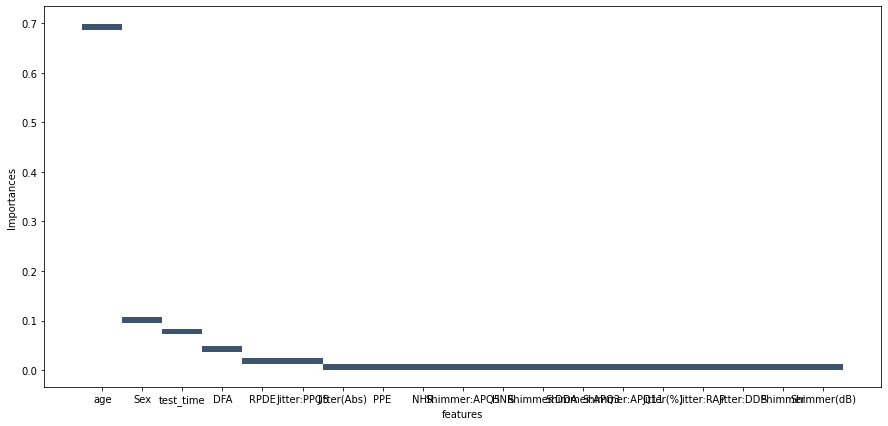

In [29]:
#Visualizing the importance
plt.figure(figsize=(15,7))
sns.histplot(data=importance, x='features', y='Importances')

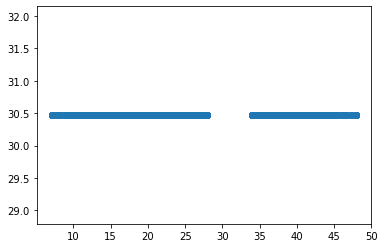

In [30]:
# ploting difference in actual and predicted values for participant-level spliting

plt.scatter(y_test, pred2)
plt.show()

As shown, the difference is not usual,this suggest that the model is not capable to get generalized on unseen participant data due to very small size of dataset.

This project estimates symptoms severity based on some voice measurments. It does not detect or diagnose parkinson's disease or prove that voice measurements can replace clinical assessments. 